In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [ ]:
df=pd.read_csv('/content/Social_Network_Ads.csv')

In [ ]:
df.head()

,User ID,Gender,Age,EstimatedSalary,Purchased
0,15624510,Male,19,19000,0
1,15810944,Male,35,20000,0
2,15668575,Female,26,43000,0
3,15603246,Female,27,57000,0
4,15804002,Male,19,76000,0


In [ ]:
df.tail()

,User ID,Gender,Age,EstimatedSalary,Purchased
395,15691863,Female,46,41000,1
396,15706071,Male,51,23000,1
397,15654296,Female,50,20000,1
398,15755018,Male,36,33000,0
399,15594041,Female,49,36000,1


In [ ]:
df.describe()

,User ID,Age,EstimatedSalary,Purchased
count,4.000000e+02,400.000000,400.000000,400.000000
mean,1.569154e+07,37.655000,69742.500000,0.357500
std,7.165832e+04,10.482877,34096.960282,0.479864
min,1.556669e+07,18.000000,15000.000000,0.000000
25%,1.562676e+07,29.750000,43000.000000,0.000000
50%,1.569434e+07,37.000000,70000.000000,0.000000
75%,1.575036e+07,46.000000,88000.000000,1.000000
max,1.581524e+07,60.000000,150000.000000,1.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 400 entries, 0 to 399
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   User ID          400 non-null    int64 
 1   Gender           400 non-null    object
 2   Age              400 non-null    int64 
 3   EstimatedSalary  400 non-null    int64 
 4   Purchased        400 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 15.8+ KB


In [ ]:
df.shape

(400, 5)

In [ ]:
df.columns

Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

<Axes: xlabel='Gender', ylabel='count'>

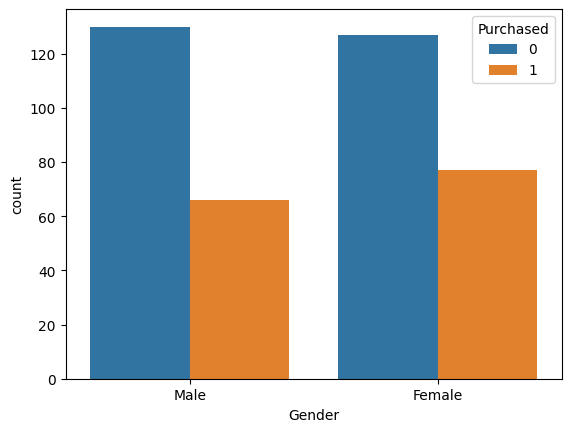

In [ ]:
sns.countplot(x="Gender",data=df,hue="Purchased")

<Axes: xlabel='EstimatedSalary', ylabel='count'>

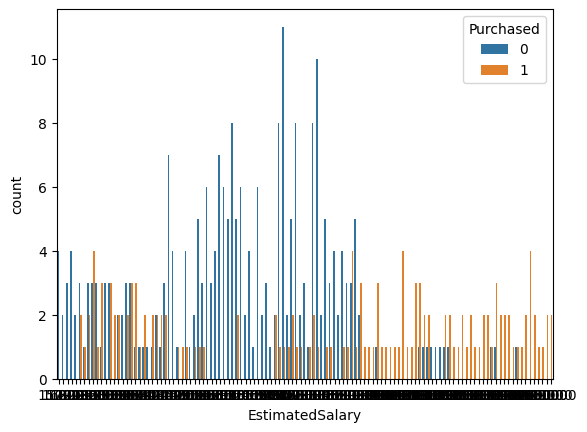

In [ ]:
sns.countplot(x="EstimatedSalary",data=df,hue="Purchased")

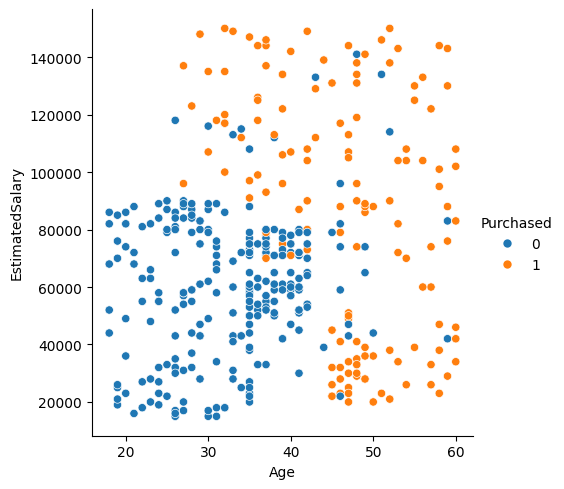

In [ ]:
sns.relplot(x="Age",y="EstimatedSalary",data=df,hue="Purchased")

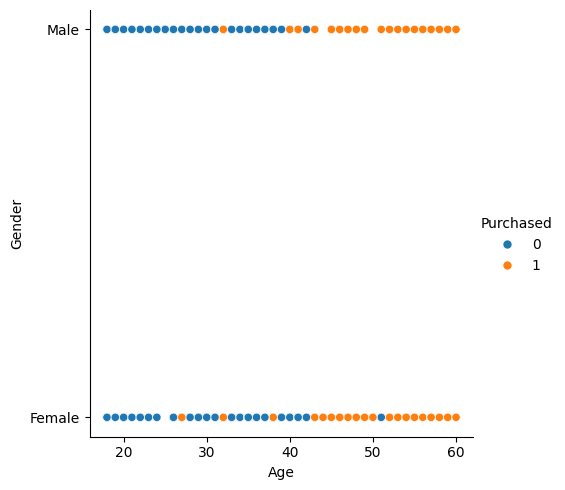

In [ ]:
sns.relplot(x="Age",y="Gender",data=df,hue="Purchased")

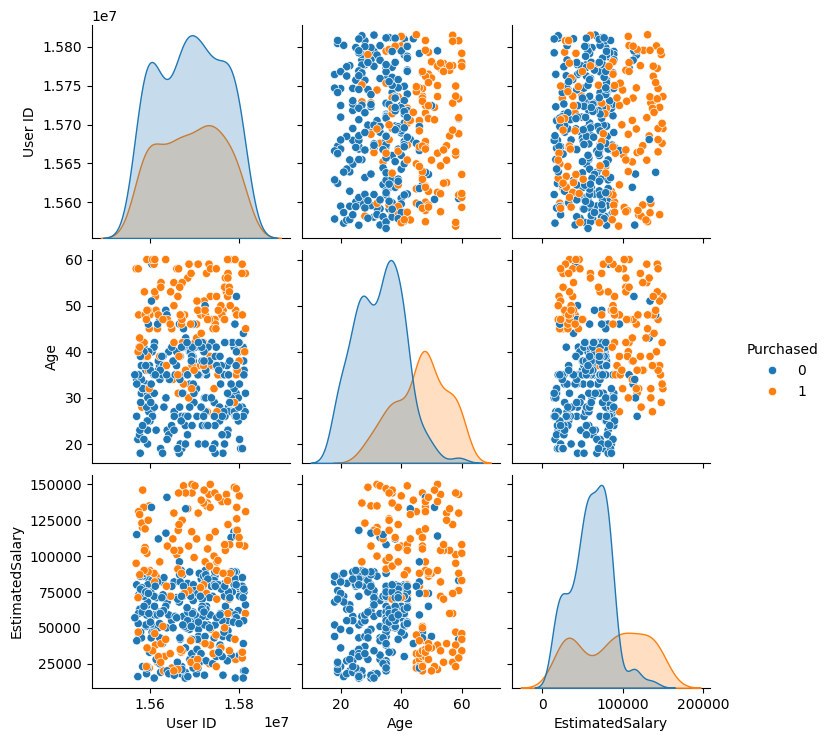

In [ ]:
sns.pairplot(df,hue="Purchased")

<Axes: >

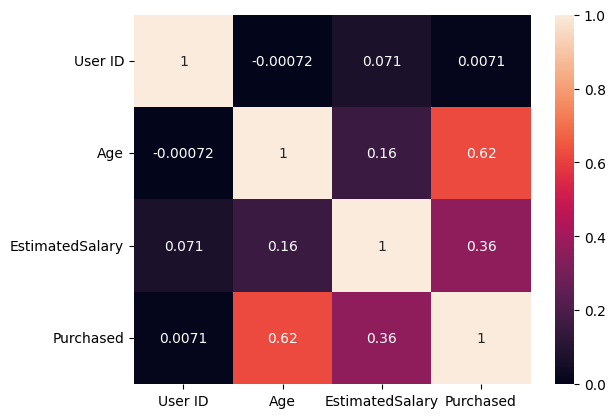

In [ ]:
sns.heatmap(df.corr(numeric_only=True),annot=True)

In [ ]:
df.isnull().sum()

,0
User ID,0
Gender,0
Age,0
EstimatedSalary,0
Purchased,0


In [ ]:
from sklearn.preprocessing import MinMaxScaler
sc=MinMaxScaler()
dl=['Purchased','Gender']
data1=sc.fit_transform(df.drop(dl,axis=1))

In [ ]:
con_data=df[['Purchased','Gender']]

In [ ]:
df.columns

Index(['User ID', 'Gender', 'Age', 'EstimatedSalary', 'Purchased'], dtype='object')

In [ ]:
data2=pd.DataFrame(data1,columns=['User ID', 'Age', 'EstimatedSalary'])

In [ ]:
final_data=pd.concat([data2,con_data],axis=1)

In [ ]:
final_data

,User ID,Age,EstimatedSalary,Purchased,Gender
0,0.232636,0.023810,0.029630,0,Male
1,0.982732,0.404762,0.037037,0,Male
2,0.409926,0.190476,0.207407,0,Female
3,0.147083,0.214286,0.311111,0,Female
4,0.954801,0.023810,0.451852,0,Male
...,...,...,...,...,...
395,0.503623,0.666667,0.192593,1,Female
396,0.560787,0.785714,0.059259,1,Male
397,0.352477,0.761905,0.037037,1,Female
398,0.757720,0.428571,0.133333,0,Male


In [ ]:
x=final_data.drop(['Purchased','Gender','User ID'], axis=1)
y=final_data['Purchased']

In [ ]:
x

,Age,EstimatedSalary
0,0.023810,0.029630
1,0.404762,0.037037
2,0.190476,0.207407
3,0.214286,0.311111
4,0.023810,0.451852
...,...,...
395,0.666667,0.192593
396,0.785714,0.059259
397,0.761905,0.037037
398,0.428571,0.133333


In [ ]:
y

,Purchased
0,0
1,0
2,0
3,0
4,0
...,...
395,1
396,1
397,1
398,0


In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=45)

In [ ]:
from sklearn.linear_model import LogisticRegression
clf=LogisticRegression()
clf.fit(x_train,y_train)

LogisticRegression()

In [ ]:
y_pred=clf.predict(x_test)

In [ ]:
y_pred

array([1, 1, 0, 1, 0, 0, 0, 0, 0, 1, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1,
       0, 1, 1, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 0, 1, 0, 0, 0, 0, 1, 1, 0, 0, 0, 1, 0, 1, 0, 0, 0, 0, 0, 1,
       0, 0, 1, 0, 1, 0, 0, 0, 1, 0, 0, 0])

In [ ]:
y_pred_prob=clf.predict_proba(x_test)

In [ ]:
y_pred_prob

array([[0.2333855 , 0.7666145 ],
       [0.27502809, 0.72497191],
       [0.62642611, 0.37357389],
       [0.33134442, 0.66865558],
       [0.67288055, 0.32711945],
       [0.9794674 , 0.0205326 ],
       [0.76340358, 0.23659642],
       [0.74810305, 0.25189695],
       [0.87578468, 0.12421532],
       [0.29808113, 0.70191887],
       [0.84796412, 0.15203588],
       [0.45395157, 0.54604843],
       [0.95643929, 0.04356071],
       [0.25174626, 0.74825374],
       [0.76647137, 0.23352863],
       [0.94497433, 0.05502567],
       [0.89258394, 0.10741606],
       [0.66431393, 0.33568607],
       [0.96781325, 0.03218675],
       [0.97618934, 0.02381066],
       [0.67477277, 0.32522723],
       [0.1013432 , 0.8986568 ],
       [0.80286525, 0.19713475],
       [0.61329629, 0.38670371],
       [0.8785505 , 0.1214495 ],
       [0.95715108, 0.04284892],
       [0.58970136, 0.41029864],
       [0.86959449, 0.13040551],
       [0.65177549, 0.34822451],
       [0.72109198, 0.27890802],
       [0.

In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    recall_score,
    precision_score,
    classification_report,
    f1_score
)

In [ ]:
cm=confusion_matrix(y_test,y_pred)
print(cm)

[[60  2]
 [12 26]]


In [ ]:
recall=recall_score(y_test,y_pred)
recall

0.6842105263157895

In [ ]:
ac=accuracy_score(y_test,y_pred)
recall

0.6842105263157895

In [ ]:
precision=precision_score(y_test,y_pred)
precision

0.9285714285714286

In [ ]:
f1score=f1_score(y_test,y_pred)
f1score

0.7878787878787878

In [ ]:
cr=classification_report(y_test,y_pred)
print(cr)

              precision    recall  f1-score   support

           0       0.83      0.97      0.90        62
           1       0.93      0.68      0.79        38

    accuracy                           0.86       100
   macro avg       0.88      0.83      0.84       100
weighted avg       0.87      0.86      0.85       100

